In [ ]:
#Importing the Libraries
import numpy as np
import pandas as pd
import datetime
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt, numpy as np
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import AgglomerativeClustering
from matplotlib.colors import ListedColormap
from sklearn import metrics
import warnings
import sys
if not sys.warnoptions:
    warnings.simplefilter("ignore")
np.random.seed(42)

# Loading Data

Data ini bersumber dari kaggle (https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis) berisi catatan pelanggan dari sebuah perusahaan grosir yang mencerminkan perilaku belanja masing-masing pelanggan. Informasi yang tersedia mencakup aspek seperti tingkat pendidikan, pendapatan, jumlah anak, umur, durasi langganan, serta pola pembelian berbagai jenis produk (seperti daging, ikan, dan lain-lain).



In [ ]:


# Link ke file CSV (raw GitHub)
url = "https://raw.githubusercontent.com/ulfadwyh002/K-Means_Clustering/main/marketing_campaign.csv"

# Membaca file CSV dengan pemisah tab
data = pd.read_csv(url, sep='\t')

# Menampilkan 5 baris pertama
print(data.head())


     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  AcceptedCmp3  \
0  04-09-2012       58       635  ...                  7             0   
1  08-03-2014       38        11  ...                  5             0   
2  21-08-2013       26       426  ...                  4             0   
3  10-02-2014       26        11  ...                  6             0   
4  19-01-2014       94       173  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  Complain  \
0             0

# Data Cleaning

In [ ]:
# Menampilkan jumlah baris dan kolom
print("=== Ukuran Dataset ===")
print(f"Total Baris: {data.shape[0]}")
print(f"Total Kolom: {data.shape[1]}")

=== Ukuran Dataset ===
Total Baris: 2240
Total Kolom: 29


Dataset ini terdiri dari 2.240 baris data yang masing-masing merepresentasikan satu pelanggan, serta 29 kolom.

In [ ]:
data.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')



*   Untuk memudahkan pemahaman dan analisis data, dilakukan proses rename atau penggantian nama kolom dengan istilah yang lebih deskriptif dan mudah dipahami




In [ ]:
data.rename(columns={
    'ID': 'ID_Pelanggan',
    'Year_Birth': 'Tahun_Lahir',
    'Education': 'Pendidikan',
    'Marital_Status': 'Status_Pernikahan',
    'Income': 'Pendapatan',
    'Kidhome': 'Anak_Kecil',
    'Teenhome': 'Remaja',
    'Dt_Customer': 'Tanggal_Daftar',
    'Recency': 'Hari_Terakhir_Belanja',
    'MntWines': 'Belanja_Wine',
    'MntFruits': 'Belanja_Buah',
    'MntMeatProducts': 'Belanja_Daging',
    'MntFishProducts': 'Belanja_Ikan',
    'MntSweetProducts': 'Belanja_Manis',
    'MntGoldProds': 'Belanja_Emas',
    'NumDealsPurchases': 'Jumlah_Pembelian_Promo',
    'NumWebPurchases': 'Pembelian_Web',
    'NumCatalogPurchases': 'Pembelian_Katalog',
    'NumStorePurchases': 'Pembelian_Toko',
    'NumWebVisitsMonth': 'Kunjungan_Web_Bulanan',
    'AcceptedCmp1': 'promosi1',
    'AcceptedCmp2': 'promosi2',
    'AcceptedCmp3': 'promosi3',
    'AcceptedCmp4': 'promosi4',
    'AcceptedCmp5': 'promosi5',
    'Complain': 'Keluhan',
    'Z_CostContact': 'Biaya_Kontak',
    'Z_Revenue': 'Pendapatan_Tambahan',
    'Response': 'Respon_Kampanye',
}, inplace=True)


In [ ]:
#Information on features
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            2240 non-null   int64  
 1   Tahun_Lahir             2240 non-null   int64  
 2   Pendidikan              2240 non-null   object 
 3   Status_Pernikahan       2240 non-null   object 
 4   Pendapatan              2216 non-null   float64
 5   Anak_Kecil              2240 non-null   int64  
 6   Remaja                  2240 non-null   int64  
 7   Tanggal_Daftar          2240 non-null   object 
 8   Hari_Terakhir_Belanja   2240 non-null   int64  
 9   Belanja_Wine            2240 non-null   int64  
 10  Belanja_Buah            2240 non-null   int64  
 11  Belanja_Daging          2240 non-null   int64  
 12  Belanja_Ikan            2240 non-null   int64  
 13  Belanja_Manis           2240 non-null   int64  
 14  Belanja_Emas            2240 non-null   



*   Merubah Tipe Data




In [ ]:
# Mengonversi kolom "Tanggal_Daftar" menjadi format datetime
data["Tanggal_Daftar"] = pd.to_datetime(data["Tanggal_Daftar"], format="%d-%m-%Y")




*   Tahap ini dilakukan penghapusan terhadap seluruh baris data yang memiliki nilai kosong (missing values) menggunakan fungsi dropna(). Tujuannya adalah untuk memastikan kualitas data yang digunakan dalam analisis berada dalam kondisi lengkap dan tidak mengandung informasi yang hilang, sehingga hasil analisis tidak bias atau menyesatkan.




In [ ]:
# Menghapus nilai yang kosong (NA) dari data
data = data.dropna()

# Menampilkan jumlah data setelah baris dengan nilai kosong dihapus
print("Jumlah total data setelah menghapus baris yang memiliki nilai kosong adalah:", len(data))


Jumlah total data setelah menghapus baris yang memiliki nilai kosong adalah: 2216




*   Tahap ini dilakukan untuk mengetahui tanggal pendaftaran pelanggan paling awal dan paling baru, sehingga dapat digunakan dalam analisis berbasis waktu atau loyalitas pelanggan.




In [ ]:

# Mengambil tanggal dari kolom "Tanggal_Daftar"
dates = data["Tanggal_Daftar"].dt.date.tolist()

# Menampilkan tanggal enrolmen pelanggan terbaru dan terlama
print("Tanggal enrolmen pelanggan terbaru dalam catatan:", max(dates))
print("Tanggal enrolmen pelanggan terlama dalam catatan:", min(dates))


Tanggal enrolmen pelanggan terbaru dalam catatan: 2014-06-29
Tanggal enrolmen pelanggan terlama dalam catatan: 2012-07-30


In [ ]:
days = []
d1 = max(dates) #Pelanggan Terbaru
for i in dates:
    delta = d1 - i
    days.append(delta.days) # Ambil hanya jumlah hari dari objek timedelta
data["Lama_Terdaftar"] = days
# Baris terakhir yang bermasalah dihapus karena tidak lagi diperlukan

/tmp/ipython-input-10-3835312013.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Lama_Terdaftar"] = days




*   Tahap ini bertujuan untuk membuat fitur baru bernama Lama_Terdaftar yang menunjukkan lama waktu (dalam hari) sejak seorang pelanggan mendaftar hingga pelanggan terbaru. Fitur ini berguna untuk menganalisis loyalitas atau keterlibatan pelanggan berdasarkan durasi hubungan mereka dengan perusahaan.






*   Tahap ini bertujuan untuk mengetahui jumlah dan distribusi kategori dalam fitur Status_Pernikahan dan Pendidikan, sehingga dapat memberikan gambaran awal tentang karakteristik demografis pelanggan.




In [ ]:
print("Total kategori dalam fitur Status_Pernikahan:\n", data["Status_Pernikahan"].value_counts(), "\n")
print("Total kategori dalam fitur Pendidikan:\n", data["Pendidikan"].value_counts())


Total kategori dalam fitur Status_Pernikahan:
 Status_Pernikahan
Married     857
Together    573
Single      471
Divorced    232
Widow        76
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64 

Total kategori dalam fitur Pendidikan:
 Pendidikan
Graduation    1116
PhD            481
Master         365
2n Cycle       200
Basic           54
Name: count, dtype: int64






*   Tahap ini dilakukan untuk menjaga konsistensi tipe data pada kolom belanja, sehingga seluruh nilai dalam kolom tersebut dapat diolah secara numerik






In [ ]:
numeric_columns = [
    'Belanja_Wine',
    'Belanja_Buah',
    'Belanja_Daging',
    'Belanja_Ikan',
    'Belanja_Manis',
    'Belanja_Emas'
]

for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')

/tmp/ipython-input-12-805471713.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = pd.to_numeric(data[col], errors='coerce')


In [ ]:

# Menghitung usia pelanggan saat ini
data["Umur"] = 2025 - data["Tahun_Lahir"]  # Menghitung umur berdasarkan tahun lahir

# Menambahkan fitur pengeluaran (Total pengeluaran untuk berbagai item) :
# Untuk mengetahui total pengeluaran pelanggan dari semua kategori produk, yang menggambarkan nilai konsumsi atau loyalitas terhadap perusahaan.

data["pengeluaran"] = (
    data["Belanja_Wine"] +
    data["Belanja_Buah"] +
    data["Belanja_Daging"] +
    data["Belanja_Ikan"] +
    data["Belanja_Manis"] +
    data["Belanja_Emas"]
)

# Untuk menyederhanakan dan menstandarkan kategori dalam fitur status pernikahan agar lebih mudah dianalisis.
data["Status"] = data["Status_Pernikahan"].replace({
    "Married": "Menikah",
    "Together": "Pasangan",
    "Single": "Sendiri",
    "Divorced": "Cerai",
    "Widow": "Janda",
    "Alone": "Sendiri",
    "Absurd": "Tanpa_Status",
    "YOLO": "Jomblo"
})

# Menambahkan Fitur yang menunjukkan total anak yang tinggal di rumah.
data["Anak"] = data["Anak_Kecil"] + data["Remaja"]

# Menambahkan Fitur untuk mengidentifikasi apakah pelanggan merupakan orang tua atau tidak (memiliki anak di rumah)
data["Jumlah_Anak"] = np.where(data["Anak"] > 0, 1, 0)

# Mengelompokkan mengelompokkan level pendidikan menjadi tiga kategori utama (Undergraduate, Graduate, Postgraduate) agar lebih terstruktur.
data["Pendidikan"] = data["Pendidikan"].replace({
    "Basic": "Undergraduate",
    "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate",
    "PhD": "Postgraduate"
})

# Menyederhanakan nama kolom agar lebih ringkas dan konsisten, terutama pada kolom belanja produk.
data = data.rename(columns={
    "Belanja_Wine": "Wines",
    "Belanja_Buah": "Fruits",
    "Belanja_Daging": "Meat",
    "Belanja_Ikan": "Fish",
    "Belanja_Manis": "Sweets",
    "Belanja_Emas": "Gold"
})

# membersihkan data dari fitur yang tidak dibutuhkan
to_drop = ["Status_Pernikahan", "Tanggal_Daftar", "Biaya_Kontak", "Pendapatan_Tambahan", "Tahun_Lahir", "ID_Pelanggan"]
data = data.drop(to_drop, axis=1)

# Menampilkan DataFrame yang telah diproses
print(data.head())

     Pendidikan  Pendapatan  Anak_Kecil  Remaja  Hari_Terakhir_Belanja  Wines  \
0      Graduate     58138.0           0       0                     58    635   
1      Graduate     46344.0           1       1                     38     11   
2      Graduate     71613.0           0       0                     26    426   
3      Graduate     26646.0           1       0                     26     11   
4  Postgraduate     58293.0           1       0                     94    173   

   Fruits  Meat  Fish  Sweets  ...  promosi1  promosi2  Keluhan  \
0      88   546   172      88  ...         0         0        0   
1       1     6     2       1  ...         0         0        0   
2      49   127   111      21  ...         0         0        0   
3       4    20    10       3  ...         0         0        0   
4      43   118    46      27  ...         0         0        0   

   Respon_Kampanye  Lama_Terdaftar  Umur  pengeluaran    Status  Anak  \
0                1             663   

/tmp/ipython-input-13-2060776358.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Umur"] = 2025 - data["Tahun_Lahir"]  # Menghitung umur berdasarkan tahun lahir
/tmp/ipython-input-13-2060776358.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["pengeluaran"] = (
/tmp/ipython-input-13-2060776358.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https:



*   Ringkasan Statistik Deskriptif Data Numerik



In [ ]:
data.describe()

,Pendapatan,Anak_Kecil,Remaja,Hari_Terakhir_Belanja,Wines,Fruits,Meat,Fish,Sweets,Gold,...,promosi5,promosi1,promosi2,Keluhan,Respon_Kampanye,Lama_Terdaftar,Umur,pengeluaran,Anak,Jumlah_Anak
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,...,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000
mean,52247.251354,0.441787,0.505415,49.012635,305.091606,26.356047,166.995939,37.637635,27.028881,43.965253,...,0.073105,0.064079,0.013538,0.009477,0.150271,353.521209,56.179603,607.075361,0.947202,0.714350
std,25173.076661,0.536896,0.544181,28.948352,337.327920,39.793917,224.283273,54.752082,41.072046,51.815414,...,0.260367,0.244950,0.115588,0.096907,0.357417,202.434667,11.985554,602.900476,0.749062,0.451825
min,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,29.000000,5.000000,0.000000,0.000000
25%,35303.000000,0.000000,0.000000,24.000000,24.000000,2.000000,16.000000,3.000000,1.000000,9.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,180.000000,48.000000,69.000000,0.000000,0.000000
50%,51381.500000,0.000000,0.000000,49.000000,174.500000,8.000000,68.000000,12.000000,8.000000,24.500000,...,0.000000,0.000000,0.000000,0.000000,0.000000,355.500000,55.000000,396.500000,1.000000,1.000000
75%,68522.000000,1.000000,1.000000,74.000000,505.000000,33.000000,232.250000,50.000000,33.000000,56.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,529.000000,66.000000,1048.000000,1.000000,1.000000
max,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,262.000000,321.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,699.000000,132.000000,2525.000000,3.000000,1.000000




*   Memvisualisasikan hubungan antar fitur numerik seperti
 Pendapatan, Hari_Terakhir_Belanja, Umur, pengeluaran, dan Jumlah_Anak, dalam bentuk pairplot, serta mengamati pola perbedaan berdasarkan status Jumlah_Anak : apakah pelanggan memiliki anak atau tidak. (0 = Tidak Memiliki anak, 1 = Memiliki Anak)



Relative Plot Of Some Selected Features: A Data Subset


<Figure size 800x550 with 0 Axes>

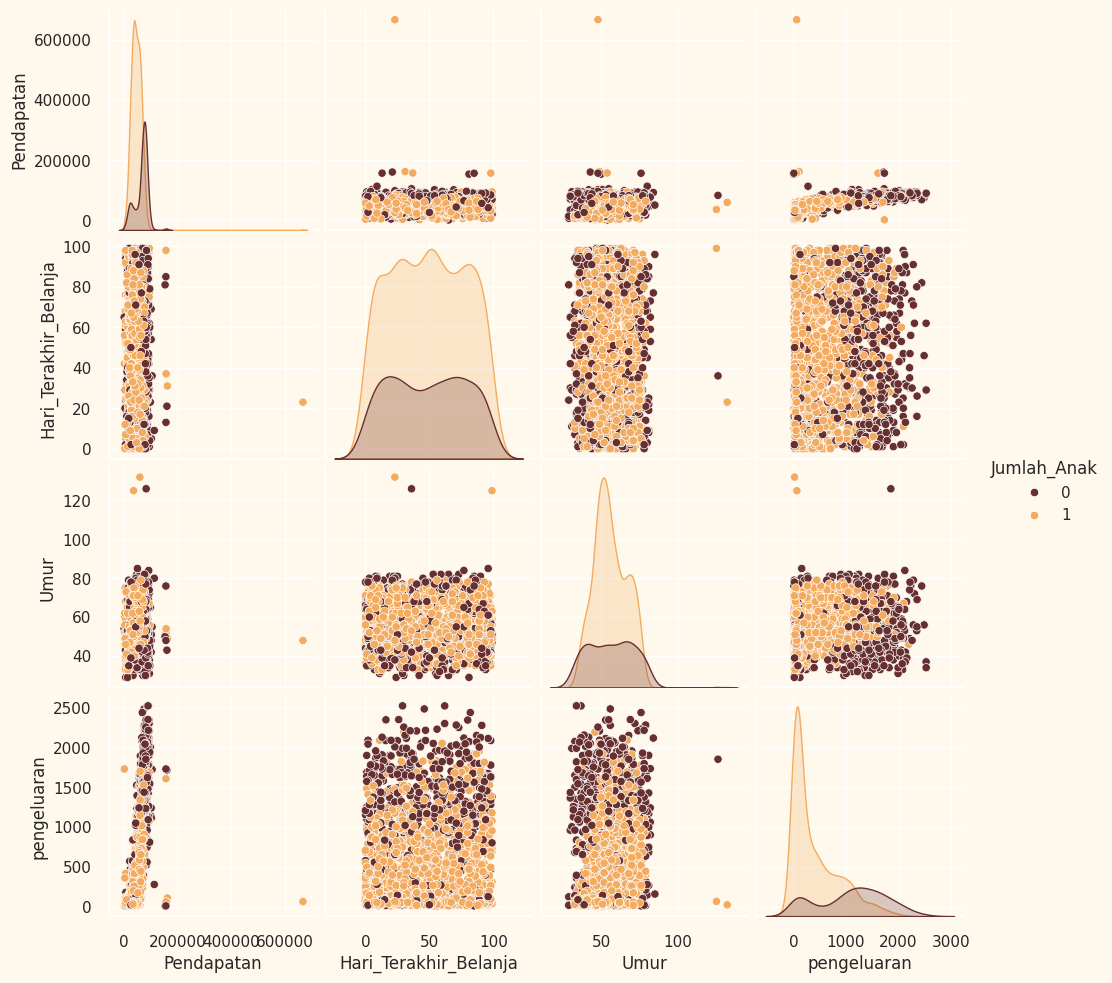

In [ ]:

# Set up colors preferences
sns.set(rc={"axes.facecolor": "#FFF9ED", "figure.facecolor": "#FFF9ED"})
pallet = ["#682F2F", "#9E726F", "#D6B2B1", "#B9C0C9", "#9F8A78", "#F3AB60"]
cmap = colors.ListedColormap(pallet)

# Plotting following features (remove 'Tanggal_Daftar' since it was dropped)
To_Plot = ["Pendapatan", "Hari_Terakhir_Belanja", "Umur", "pengeluaran", "Jumlah_Anak"]

print("Relative Plot Of Some Selected Features: A Data Subset")
plt.figure()
sns.pairplot(data[To_Plot], hue="Jumlah_Anak", palette=["#682F2F", "#F3AB60"]) #
plt.show()


In [ ]:
# Mengeluarkan jumlah kemunculan setiap nilai dalam kolom Status_Pernikahan
status_counts = data["Umur"].value_counts()
print("Jumlah kemunculan setiap nilai dalam kolom Umur:\n", status_counts)


Jumlah kemunculan setiap nilai dalam kolom Umur:
 Umur
49     89
54     86
50     83
53     78
47     76
55     75
60     74
52     72
56     70
51     69
69     55
46     53
67     52
73     52
48     52
57     51
59     50
66     50
71     49
65     49
70     48
62     44
58     44
63     44
43     44
74     42
68     41
39     41
42     41
61     41
45     39
41     38
44     38
72     35
64     35
40     32
76     30
75     29
36     29
37     29
38     27
77     21
35     18
78     16
79     16
34     15
33     13
80      8
81      7
82      6
30      5
32      5
31      3
29      2
125     1
132     1
126     1
84      1
85      1
Name: count, dtype: int64


In [ ]:
# Mengeluarkan jumlah kemunculan setiap nilai dalam kolom Status_Pernikahan
status_counts = data["Pendapatan"].value_counts()
print("Jumlah kemunculan setiap nilai dalam kolom Umur:\n", status_counts)


Jumlah kemunculan setiap nilai dalam kolom Umur:
 Pendapatan
7500.0     12
35860.0     4
18929.0     3
46098.0     3
67445.0     3
           ..
5305.0      1
80617.0     1
38054.0     1
88325.0     1
41769.0     1
Name: count, Length: 1974, dtype: int64



*   Menghapus data pelanggan yang usianya 90 tahun ke atas, karena usia tersebut dianggap outlier atau tidak realistis dalam konteks bisnis ritel.

In [ ]:
# Menghapus outlier berdasarkan batas maksimum umur dan pendapatan
data = data[data["Umur"] < 90]
data = data[data["Pendapatan"] < 600000]

print("Jumlah data setelah menghapus outlier adalah:", len(data))


Jumlah data setelah menghapus outlier adalah: 2212


# DATA PREPROCESSING

In [ ]:
# Mendapatkan daftar variabel kategorikal
s = (data.dtypes == 'object')
kolom_kategorikal = list(s[s].index)

print("Variabel kategorikal dalam dataset:", kolom_kategorikal)


Variabel kategorikal dalam dataset: ['Pendidikan', 'Status']




*   Tahap ini bertujuan untuk mengubah fitur kategorikal (tipe object) menjadi bentuk numerik menggunakan Label Encoding, agar data dapat diproses oleh algoritma machine learning seperti KMeans yang hanya menerima input numerik. Konversi ini memastikan seluruh fitur siap.













In [ ]:
#Label Encoding the object dtypes.
LE=LabelEncoder()
for i in kolom_kategorikal:
    data[i]=data[[i]].apply(LE.fit_transform)

print("All features are now numerical")

All features are now numerical




*   Tahap selanjutnya digunakan untuk menstandarkan nilai pada fitur numerik, agar semua variabel berada dalam skala yang sebanding. Misalnya, kolom seperti pendapatan bisa memiliki nilai jutaan, sedangkan kolom seperti umur hanya memiliki nilai puluhan. Jika tidak distandarkan, fitur dengan skala besar dapat mendominasi proses analisis, sehingga fitur lain menjadi kurang berpengaruh.

*   Dengan melakukan standarisasi, setiap fitur akan memiliki rata-rata 0 dan standar deviasi 1, sehingga seluruh variabel memiliki kontribusi yang seimbang dalam analisis seperti clustering.



In [ ]:
#Creating a copy of data
ds = data.copy()
# creating a subset of dataframe by dropping the features on deals accepted and promotions
cols_del = ['promosi1', 'promosi2', 'promosi3',
                'promosi4', 'promosi5', 'Keluhan', 'Respon_Kampanye']
ds = ds.drop(cols_del, axis=1)
#Scaling
scaler = StandardScaler()
scaler.fit(ds)
scaled_ds = pd.DataFrame(scaler.transform(ds),columns= ds.columns )
print("All features are now scaled")

All features are now scaled




*   Data yang sudah dinormalisasi akan digunakan untuk tahap modeling selanjutnya




In [ ]:

print("Dataframe yang akan digunakan untuk modeling selanjutnya:")
scaled_ds.head()


Dataframe yang akan digunakan untuk modeling selanjutnya:


,Pendidikan,Pendapatan,Anak_Kecil,Remaja,Hari_Terakhir_Belanja,Wines,Fruits,Meat,Fish,Sweets,...,Pembelian_Web,Pembelian_Katalog,Pembelian_Toko,Kunjungan_Web_Bulanan,Lama_Terdaftar,Umur,pengeluaran,Status,Anak,Jumlah_Anak
0,-0.893586,0.287105,-0.822754,-0.929699,0.310353,0.977660,1.552041,1.690293,2.453472,1.483713,...,1.426865,2.503607,-0.555814,0.692181,1.527721,1.018352,1.676245,1.167459,-1.264598,-1.581139
1,-0.893586,-0.260882,1.040021,0.908097,-0.380813,-0.872618,-0.637461,-0.718230,-0.651004,-0.634019,...,-1.126420,-0.571340,-1.171160,-0.132545,-1.189011,1.274785,-0.963297,1.167459,1.404572,0.632456
2,-0.893586,0.913196,-0.822754,-0.929699,-0.795514,0.357935,0.570540,-0.178542,1.339513,-0.147184,...,1.426865,-0.229679,1.290224,-0.544908,-0.206048,0.334530,0.280110,0.478446,-1.264598,-1.581139
3,-0.893586,-1.176114,1.040021,-0.929699,-0.795514,-0.872618,-0.561961,-0.655787,-0.504911,-0.585335,...,-0.761665,-0.913000,-0.555814,0.279818,-1.060584,-1.289547,-0.920135,0.478446,0.069987,0.632456
4,0.571657,0.294307,1.040021,-0.929699,1.554453,-0.392257,0.419540,-0.218684,0.152508,-0.001133,...,0.332600,0.111982,0.059532,-0.132545,-0.951915,-1.033114,-0.307562,-0.210566,0.069987,0.632456


#DIMENSIONALITY REDUCTION



*   Kode ini dipakai untuk melakukan PCA (Principal Component Analysis), yaitu cara untuk menyederhanakan data yang banyak kolomnya jadi lebih sedikit, tapi tetap menyimpan informasi penting dari data tersebut.
Dengan PCA, kita bisa mewakili data yang rumit jadi lebih ringkas, supaya lebih gampang diproses, dianalisis, atau divisualisasikan.


*   Clustering seperti KMeans sangat sensitif terhadap data berdimensi tinggi, karena terlalu banyak fitur dapat membuat hasil pengelompokan menjadi tidak akurat (dikenal sebagai curse of dimensionality). Untuk mengatasi hal ini, PCA digunakan sebagai teknik reduksi dimensi yang menyederhanakan data tanpa banyak kehilangan informasi penting. Dengan menerapkan PCA sebelum clustering, proses pengelompokan menjadi lebih cepat, efisien, dan akurat.




In [ ]:
from sklearn.decomposition import PCA
import pandas as pd

# Melakukan PCA untuk mereduksi dimensi menjadi 3 komponen utama
pca = PCA(n_components=3)
pca.fit(scaled_ds)





PCA(n_components=3)

In [ ]:


# Hitung Z-score
z_scores = np.abs((scaled_ds - scaled_ds.mean()) / scaled_ds.std())

# Tandai data sebagai outlier jika Z > 3
outliers = (z_scores > 3).sum(axis=1)
outlier_count = (outliers > 0).sum()

print(f"Jumlah data yang mengandung outlier: {outlier_count}")
print(f"Proporsi data outlier: {outlier_count / len(scaled_ds):.2%}")


Jumlah data yang mengandung outlier: 260
Proporsi data outlier: 11.75%


In [ ]:
# Buang data dengan outlier (berdasarkan Z-score > 3)
cleaned_ds = scaled_ds[(z_scores <= 3).all(axis=1)]
print(f"Jumlah data setelah membuang outlier: {len(cleaned_ds)}")

Jumlah data setelah membuang outlier: 1952


In [ ]:
# Transformasi data ke dalam 3 komponen utama
PCA_ds = pd.DataFrame(pca.transform(scaled_ds), columns=["col1", "col2", "col3"])

# Melihat ringkasan statistik dari hasil PCA
PCA_ds.describe().T

,count,mean,std,min,25%,50%,75%,max
col1,2212.0,1.477621e-16,2.815300,-5.687312,-2.573030,-0.811703,2.388121,7.527031
col2,2212.0,-5.139550e-17,1.621826,-3.707732,-1.325508,-0.208976,1.214484,5.496483
col3,2212.0,-1.124276e-17,1.215989,-3.463160,-0.842738,-0.006322,0.837690,5.986417


# CLUSTERING



*   Tahap ini bertujuan untuk menentukan jumlah klaster (K) terbaik yang akan digunakan dalam algoritma KMeans, agar hasil pengelompokan lebih akurat — tidak terlalu sedikit dan tidak berlebihan.

*   Proses ini menggunakan Elbow Method, yaitu teknik yang memvisualisasikan hubungan antara jumlah klaster dan nilai inertia (jumlah kuadrat jarak dari tiap titik ke pusat klasternya).


Elbow Method to determine the number of clusters to be formed:


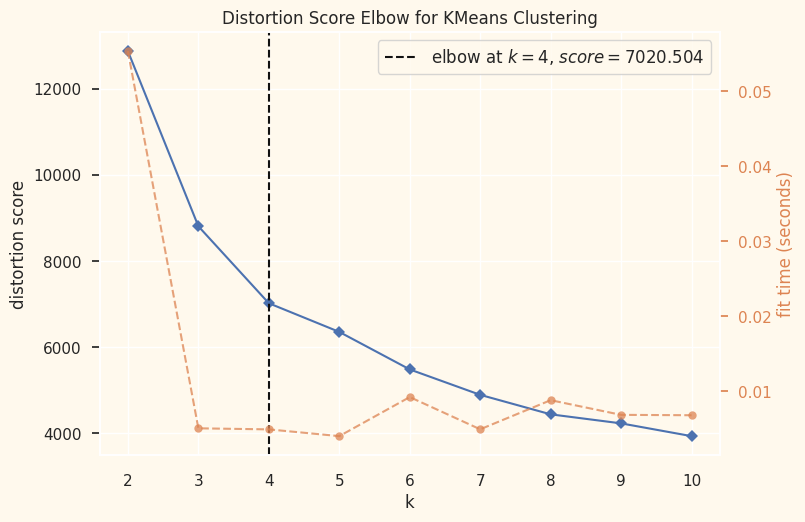

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
# Quick examination of elbow method to find numbers of clusters to make.
print('Elbow Method to determine the number of clusters to be formed:')
Elbow_M = KElbowVisualizer(KMeans(), k=10)
Elbow_M.fit(PCA_ds)
Elbow_M.show()




*   Pengecekan awal sebelum melanjutkan ke proses KMeans
*   memastikan bahwa hasil dari proses PCA sudah benar, yaitu memiliki jumlah kolom sesuai jumlah komponen utama (3)



In [ ]:
print("Kolom di PCA_ds sebelum clustering:", PCA_ds.columns)
print("Beberapa baris pertama PCA_ds sebelum clustering:\n", PCA_ds.head())

Kolom di PCA_ds sebelum clustering: Index(['col1', 'col2', 'col3'], dtype='object')
Beberapa baris pertama PCA_ds sebelum clustering:
        col1      col2      col3
0  4.672372  0.077323  2.205002
1 -2.861489  0.135225 -1.906272
2  2.515979 -0.919183 -0.095714
3 -2.648531 -1.610580  0.292186
4 -0.543668 -0.066448  0.524330


*   Visualisasi hasil klasterisasi dilakukan setelah mereduksi dimensi data menggunakan PCA (Principal Component Analysis).
*   PCA mengubah data berdimensi tinggi menjadi dua komponen utama, yaitu PC1 yang menangkap variasi terbesar dalam data, dan PC2 yang menangkap variasi terbesar berikutnya yang bersifat orthogonal (tegak lurus) terhadap PC1. Dengan demikian, data yang kompleks dapat dipetakan ke dalam dua sumbu utama secara efisien.

*   Proses ini tidak hanya memudahkan visualisasi, tetapi juga membantu dalam mengamati kedekatan antar data dan antar klaster secara menyeluruh.
*   Teknik ini didasarkan pada prinsip aljabar linier, karena PCA bekerja melalui perhitungan nilai eigen dari matriks kovarians, sementara algoritma K-Means mengelompokkan data berdasarkan jarak terdekat ke pusat klaster.


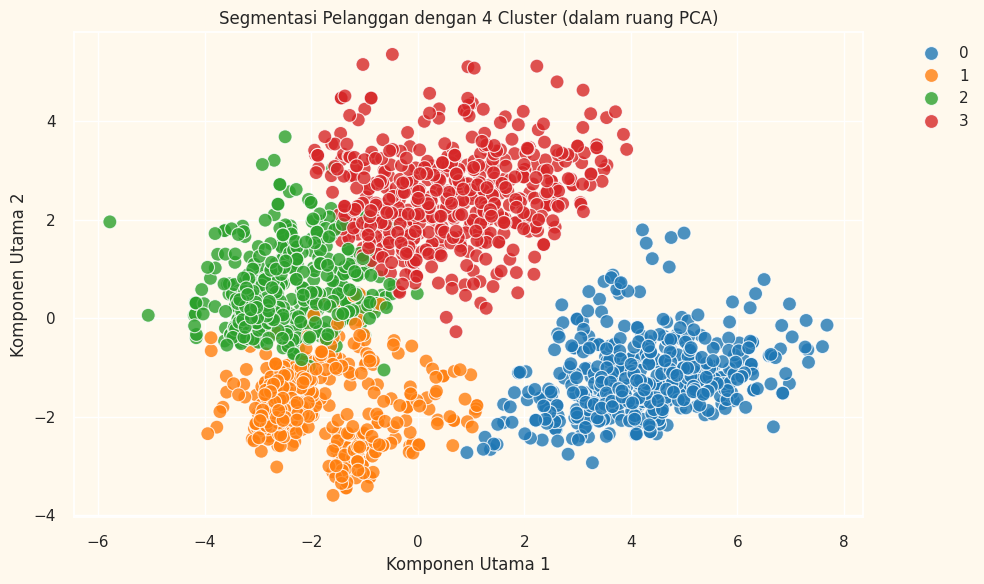

In [ ]:
# Langkah 1: Melakukan clustering pada data yang telah diskalakan
jumlah_cluster_optimal = 4  # Contoh: menetapkan jumlah cluster
kmeans = KMeans(n_clusters=jumlah_cluster_optimal, random_state=42, n_init=10)  # Menambahkan n_init agar sesuai dengan versi terbaru KMeans
label_cluster = kmeans.fit_predict(scaled_ds)  # <-- Menggunakan scaled_ds di sini

# Langkah 2: Menambahkan label cluster ke kedua DataFrame
data['Cluster'] = label_cluster
scaled_ds['Cluster'] = label_cluster

# Langkah 3: Melakukan PCA untuk visualisasi pada data yang telah diskalakan
pca = PCA(n_components=2)
PCA_ds = pca.fit_transform(scaled_ds)  # <-- Tetap menggunakan scaled_ds
PCA_ds = pd.DataFrame(PCA_ds, columns=['PC1', 'PC2'])
PCA_ds['Cluster'] = label_cluster  # Memastikan indeks tetap konsisten

# Langkah 4: Visualisasi hasil cluster dalam ruang PCA 2 dimensi
plt.figure(figsize=(10, 6))
sns.scatterplot(data=PCA_ds, x='PC1', y='PC2', hue='Cluster',
                palette=sns.color_palette('tab10', n_colors=jumlah_cluster_optimal),
                s=100, alpha=0.8)
plt.title(f'Segmentasi Pelanggan dengan {jumlah_cluster_optimal} Cluster (dalam ruang PCA)')
plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()







*   Visualisasi dengan Centroid (Vektor rata-rata dari seluruh data yang termasuk dalam satu klaster)





/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


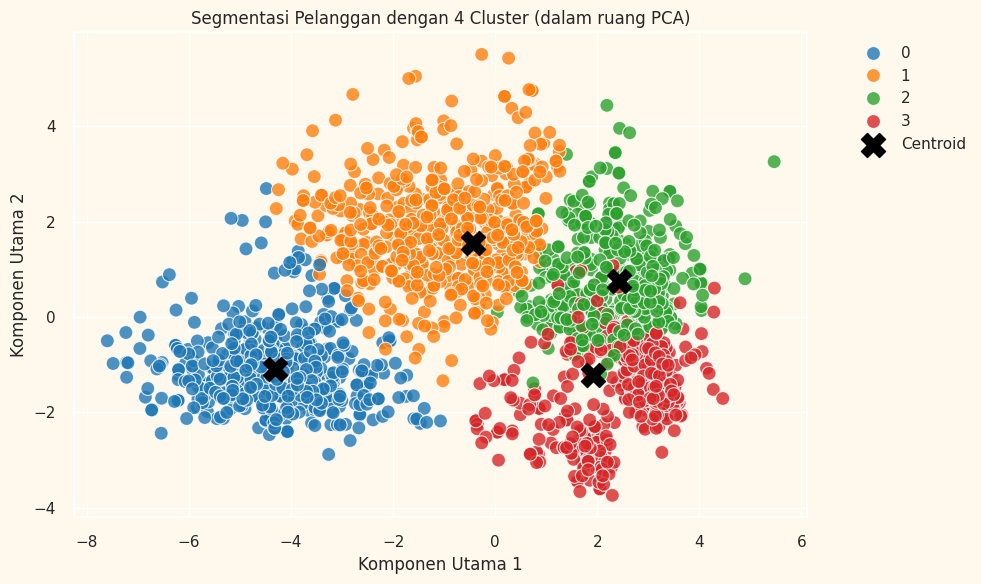

In [ ]:


# Langkah 1: Clustering
jumlah_cluster_optimal = 4
kmeans = KMeans(n_clusters=jumlah_cluster_optimal, random_state=42, n_init=10)
label_cluster = kmeans.fit_predict(scaled_ds)

# Langkah 2: Tambah label cluster
data['Cluster'] = label_cluster
scaled_ds['Cluster'] = label_cluster

# Langkah 3: PCA untuk visualisasi
pca = PCA(n_components=2)
PCA_ds = pca.fit_transform(scaled_ds)
PCA_ds = pd.DataFrame(PCA_ds, columns=['PC1', 'PC2'])
PCA_ds['Cluster'] = label_cluster

# Langkah 4: Visualisasi
plt.figure(figsize=(10, 6))
sns.scatterplot(data=PCA_ds, x='PC1', y='PC2', hue='Cluster',
                palette=sns.color_palette('tab10', n_colors=jumlah_cluster_optimal),
                s=100, alpha=0.8)

# Tambahkan centroid
centroids_pca = pca.transform(kmeans.cluster_centers_)  # Transformasi centroid ke ruang PCA
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            s=300, c='black', marker='X', label='Centroid')

plt.title(f'Segmentasi Pelanggan dengan {jumlah_cluster_optimal} Cluster (dalam ruang PCA)')
plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()




*   Tahap ini melakukan pelatihan KMeans dengan 4 klaster berdasarkan hasil reduksi dimensi PCA (kolom `PC1` dan `PC2`). Setelah model dilatih, label klaster ditambahkan ke DataFrame `data`. Terakhir, ditampilkan rata-rata setiap fitur numerik dalam tiap klaster untuk analisis karakteristik masing-masing kelompok.




In [ ]:
from sklearn.cluster import KMeans  # Import library KMeans untuk clustering

# Melatih KMeans dengan jumlah klaster = 4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)  # n_init=10 agar hasil stabil dan sesuai versi terbaru

# Memilih hanya fitur hasil PCA (tanpa kolom 'Cluster')
PCA_features = PCA_ds[['PC1', 'PC2']]  # Mengambil dua komponen utama dari hasil PCA

# Melatih model KMeans pada data hasil PCA
clusters = kmeans.fit_predict(PCA_features)  # Menentukan label klaster berdasarkan posisi di ruang PCA

# Menambahkan label klaster ke DataFrame asli
data['cluster'] = clusters  # Menyimpan hasil klaster ke kolom baru 'cluster' di data asli

# Menampilkan rata-rata nilai setiap fitur numerik per klaster
data.groupby('cluster').mean(numeric_only=True)  # Analisis karakteristik tiap klaster berdasarkan rata-rata


,Pendidikan,Pendapatan,Anak_Kecil,Remaja,Hari_Terakhir_Belanja,Wines,Fruits,Meat,Fish,Sweets,...,promosi2,Keluhan,Respon_Kampanye,Lama_Terdaftar,Umur,pengeluaran,Status,Anak,Jumlah_Anak,Cluster
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.555556,61979.868852,0.173042,0.961749,49.495446,540.555556,33.335155,173.353370,43.165756,34.052823,...,0.023679,0.009107,0.122040,413.739526,60.234973,895.147541,3.067395,1.134791,0.970856,2.990893
1,0.709402,30617.018803,0.776068,0.013675,48.504274,32.545299,6.615385,24.921368,10.432479,6.755556,...,0.000000,0.010256,0.111111,335.136752,48.256410,98.815385,3.478632,0.789744,0.767521,1.008547
2,0.555118,76268.521654,0.017717,0.041339,49.393701,604.929134,65.801181,474.557087,98.092520,68.151575,...,0.029528,0.005906,0.301181,346.710630,56.480315,1385.651575,3.460630,0.059055,0.059055,0.000000
3,0.608772,42544.870175,0.735088,0.985965,48.756140,91.557895,4.636842,32.710526,6.398246,4.489474,...,0.003509,0.010526,0.084211,321.208772,59.775439,158.110526,3.219298,1.721053,0.996491,2.010526




*   Mengevaluasi kualitas hasil clustering dengan menghitung Silhouette Score, yaitu ukuran seberapa baik objek dalam satu klaster saling mirip dan berbeda dari klaster lain. Nilai ini membantu menilai apakah jumlah klaster yang dipilih sudah tepat atau perlu diperbaiki.




In [ ]:
from sklearn.metrics import silhouette_score, silhouette_samples  # Import fungsi untuk evaluasi kualitas clustering
import pandas as pd  # Import pandas untuk manipulasi data

# Mengecek apakah kolom 'Cluster' ada di PCA_ds (hasil visualisasi sebelumnya)
# Jika ada, hapus kolom tersebut agar hanya fitur PCA yang digunakan untuk evaluasi
if 'Cluster' in PCA_ds.columns:
    PCA_ds_for_score = PCA_ds.drop(columns=['Cluster'])  # Hapus kolom 'Cluster'
else:
    PCA_ds_for_score = PCA_ds  # Gunakan langsung jika hanya berisi fitur PCA

# Menghitung skor rata-rata silhouette (semakin mendekati 1 berarti clustering semakin baik)
silhouette_avg = silhouette_score(PCA_ds_for_score, data['cluster'])  # Evaluasi keseluruhan klaster
print(f"Silhouette Score: {silhouette_avg:.3f}")  # Tampilkan hasil silhouette score

# Menghitung nilai silhouette untuk masing-masing sampel
sample_silhouette_values = silhouette_samples(PCA_ds_for_score, data['cluster'])  # Evaluasi tiap data poin

# Membuat DataFrame untuk menyimpan nilai silhouette tiap sampel dan klasternya
silhouette_df = pd.DataFrame({
    'Silhouette Score': sample_silhouette_values,  # Skor individu
    'Cluster': data['cluster']  # Label klaster dari masing-masing sampel
})


Silhouette Score: 0.512


Nilai 0.512 termasuk dalam kategori "cukup baik", artinya model K-Means dengan jumlah klaster yang digunakan (misalnya 4) sudah memetakan pola di data secara masuk akal. Namun, jika ingin meningkatkan kualitas klaster.

## Analisis Jumlah Anggota Tiap Cluster

/tmp/ipython-input-37-3735423637.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Cluster', data=PCA_ds, palette='viridis')


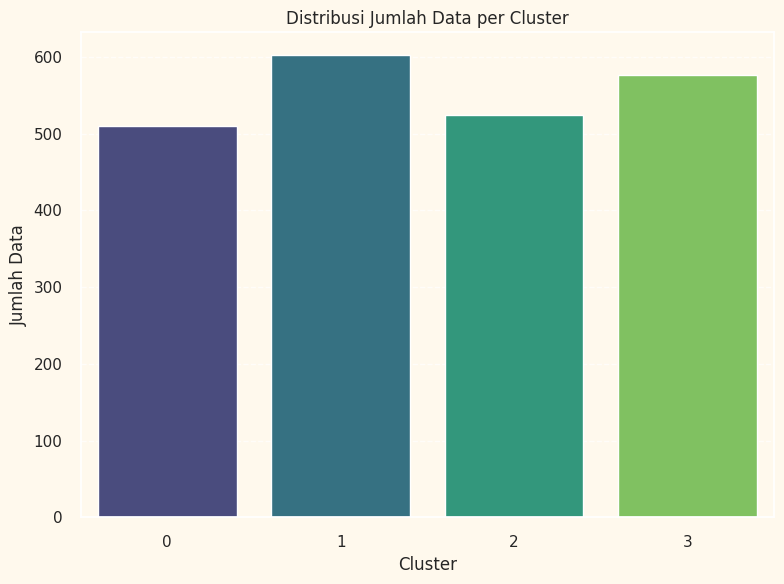

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Membuat diagram batang distribusi jumlah data per cluster
plt.figure(figsize=(8, 6))
sns.countplot(x='Cluster', data=PCA_ds, palette='viridis')

# Menambahkan label dan judul
plt.title("Distribusi Jumlah Data per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Jumlah Data")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Grafik ini menunjukkan bahwa hasil segmentasi data ke dalam 4 cluster menghasilkan pembagian yang cukup proporsional, meskipun terdapat dominasi pada Cluster 1 dan 2. Informasi ini penting sebagai evaluasi awal keberhasilan model K-Means dalam membagi data menjadi kelompok yang bermakna dan dapat ditindaklanjuti untuk analisis lanjutan seperti profiling dan klasifikasi karakteristik tiap cluster.

In [ ]:
print(data.columns)

Index(['Pendidikan', 'Pendapatan', 'Anak_Kecil', 'Remaja',
       'Hari_Terakhir_Belanja', 'Wines', 'Fruits', 'Meat', 'Fish', 'Sweets',
       'Gold', 'Jumlah_Pembelian_Promo', 'Pembelian_Web', 'Pembelian_Katalog',
       'Pembelian_Toko', 'Kunjungan_Web_Bulanan', 'promosi3', 'promosi4',
       'promosi5', 'promosi1', 'promosi2', 'Keluhan', 'Respon_Kampanye',
       'Lama_Terdaftar', 'Umur', 'pengeluaran', 'Status', 'Anak',
       'Jumlah_Anak', 'Cluster', 'cluster'],
      dtype='object')


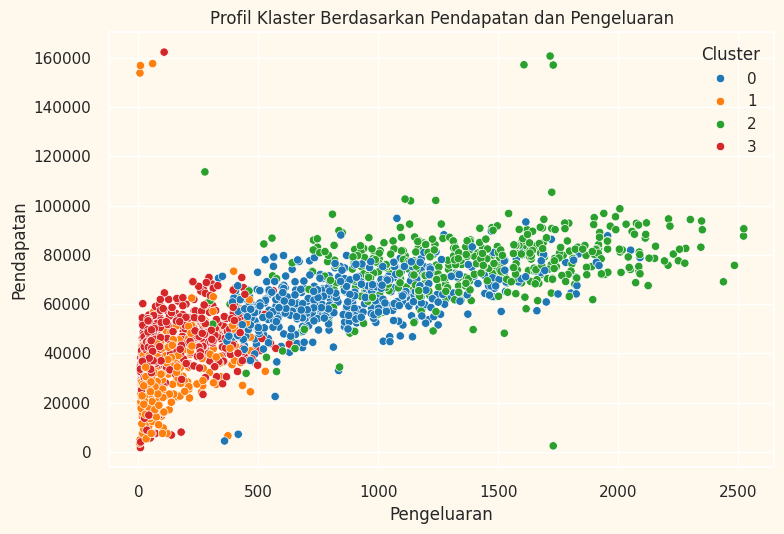

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Buat palet warna jika belum dibuat
pal = sns.color_palette('tab10', n_colors=data['cluster'].nunique())

# Plot scatter antara pendapatan dan pengeluaran
pl = sns.scatterplot(
    data=data,
    x='pengeluaran',        # pengeluaran pelanggan
    y='Pendapatan',         # pendapatan pelanggan
    hue='cluster',          # label klaster
    palette=pal
)

pl.set_title("Profil Klaster Berdasarkan Pendapatan dan Pengeluaran")
plt.xlabel("Pengeluaran")
plt.ylabel("Pendapatan")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


Visualisasi ini efektif untuk melihat bahwa ada hubungan positif antara pendapatan dan pengeluaran, namun tidak selalu linear. Clustering berhasil mengidentifikasi kelompok dengan perilaku belanja dan daya beli yang berbeda-beda


*   Klaster 0 (biru) mencerminkan pelanggan dengan pendapatan dan pengeluaran menengah, yang tergolong stabil dan cukup aktif.
*   Klaster 1 (oranye) didominasi oleh pelanggan dengan endapatan dan pengeluaran yang rendah, kemungkinan merupakan pelanggan baru atau berdaya beli rendah.
*   klaster 2 (hijau) terdiri dari pelanggan dengan pendapatan dan pengeluaran tinggi, menunjukkan kelompok pelanggan bernilai tinggi dan potensial.
*   Klaster 3 (merah) juga memiliki pendapatan rendah hingga menengah, namun pengeluarannya sangat minim, menunjukkan aktivitas belanja yang rendah.


In [ ]:
import pandas as pd

# Misalnya kamu pakai PCA_features (kolom: PC1, PC2)
centroid_df = pd.DataFrame(kmeans.cluster_centers_, columns=['PC1', 'PC2'])
print(centroid_df)


        PC1       PC2
0  0.699753  2.492537
1 -2.018334 -1.843883
2  4.285390 -1.198330
3 -2.427270  0.556289
